# 05 - Regression: predict Revenue
We train three models and compare them on test data that they have never seen. The random forest cell takes about a minute.

## Step 1: Load and split (80% train, 20% test)

In [1]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

df = pd.read_csv("../data/processed/campaigns_model_ready.csv")

X = df.drop(columns=["Revenue", "Profit_Flag"])
y = df["Revenue"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(133332, 37) (33333, 37)


## Step 2: Model 1 - Linear Regression

In [2]:
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

lr_mse = mean_squared_error(y_test, lr_pred)
lr_rmse = np.sqrt(lr_mse)
lr_mae = mean_absolute_error(y_test, lr_pred)
lr_r2 = r2_score(y_test, lr_pred)

print("MSE:", round(lr_mse, 2), "| RMSE:", round(lr_rmse, 2), "| MAE:", round(lr_mae, 2), "| R2:", round(lr_r2, 4))

MSE: 56549895398.23 | RMSE: 237802.22 | MAE: 157058.04 | R2: 0.7644


## Step 3: Model 2 - Decision Tree
A tree with no depth limit memorises the training data (overfitting). `max_depth` limits it. We try a few depths and keep the best test score.

In [3]:
depth_list = [3, 5, 8, 12, 20]

for depth in depth_list:
    tree = DecisionTreeRegressor(max_depth=depth, random_state=42)
    tree.fit(X_train, y_train)
    score = r2_score(y_test, tree.predict(X_test))
    print("max_depth =", depth, "-> test R2 =", round(score, 4))

max_depth = 3 -> test R2 = 0.7432
max_depth = 5 -> test R2 = 0.7631
max_depth = 8 -> test R2 = 0.7623
max_depth = 12 -> test R2 = 0.7306
max_depth = 20 -> test R2 = 0.6153


In [4]:
# Use the depth with the best score above (change 5 if another depth scored higher)
dt = DecisionTreeRegressor(max_depth=5, random_state=42)
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)

dt_mse = mean_squared_error(y_test, dt_pred)
dt_rmse = np.sqrt(dt_mse)
dt_mae = mean_absolute_error(y_test, dt_pred)
dt_r2 = r2_score(y_test, dt_pred)

print("MSE:", round(dt_mse, 2), "| RMSE:", round(dt_rmse, 2), "| MAE:", round(dt_mae, 2), "| R2:", round(dt_r2, 4))

MSE: 56858963968.85 | RMSE: 238451.18 | MAE: 157999.97 | R2: 0.7631


## Step 4: Model 3 - Random Forest
50 trees with `max_depth=12` keeps it fast and the saved file small. `n_jobs=-1` uses all CPU cores.

In [5]:
rf = RandomForestRegressor(n_estimators=50, max_depth=12, n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

rf_mse = mean_squared_error(y_test, rf_pred)
rf_rmse = np.sqrt(rf_mse)
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_r2 = r2_score(y_test, rf_pred)

print("MSE:", round(rf_mse, 2), "| RMSE:", round(rf_rmse, 2), "| MAE:", round(rf_mae, 2), "| R2:", round(rf_r2, 4))

MSE: 56608475066.04 | RMSE: 237925.36 | MAE: 157125.54 | R2: 0.7641


## Step 5: Compare the models

In [6]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree", "Random Forest"],
    "MSE": [lr_mse, dt_mse, rf_mse],
    "RMSE": [lr_rmse, dt_rmse, rf_rmse],
    "MAE": [lr_mae, dt_mae, rf_mae],
    "R2": [lr_r2, dt_r2, rf_r2],
}).round(3)

results

,Model,MSE,RMSE,MAE,R2
0,Linear Regression,5.654990e+10,237802.219,157058.038,0.764
1,Decision Tree,5.685896e+10,238451.177,157999.974,0.763
2,Random Forest,5.660848e+10,237925.356,157125.544,0.764


**How to read this:** R2 is the share of Revenue variation the model explains. The brief sets a target of 0.95. In this dataset the cost, conversions and engagement columns explain about 76% of Revenue, and all three models land at nearly the same score. The remaining variation is the revenue earned per conversion, which none of the columns predict. Reaching 0.95 would need ROI or a Revenue-based column as an input, and that is data leakage. Report the real score and explain this in your documentation.

## Step 6: Actual vs predicted (random forest)

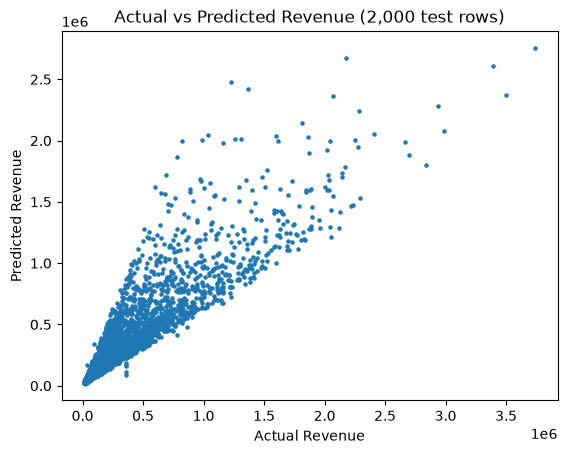

In [7]:
compare = pd.DataFrame({"Actual": y_test, "Predicted": rf_pred}).sample(2000, random_state=42)

plt.scatter(compare["Actual"], compare["Predicted"], s=5)
plt.xlabel("Actual Revenue")
plt.ylabel("Predicted Revenue")
plt.title("Actual vs Predicted Revenue (2,000 test rows)")
plt.show()

## Step 7: Which inputs matter most?

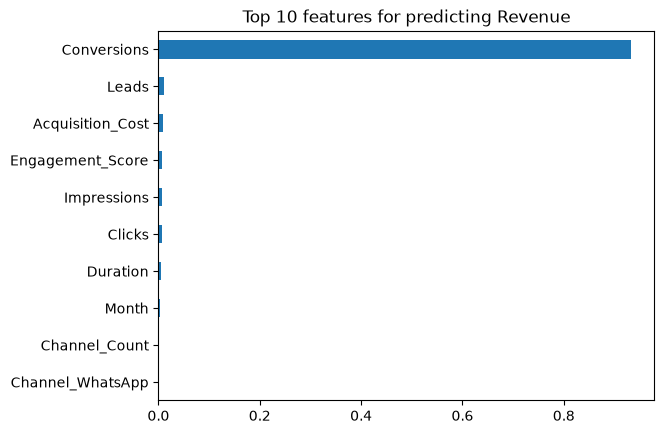

In [8]:
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
importance.head(10).sort_values().plot(kind="barh")
plt.title("Top 10 features for predicting Revenue")
plt.show()

## Step 8: Save the best model
The three scores are very close. We save the random forest. If another model scored clearly higher, put `lr` or `dt` here instead.

In [9]:
best_model = rf

joblib.dump(best_model, "../models/revenue_model.pkl")
print("Saved!")

Saved!
